<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Apache Tika Document Extraction](https://github.com/Query-farm/vgi-tika)

Pull text and metadata out of PDFs, Office files and other documents, detect their type and language, and OCR scanned images.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-tika/blob/main/notebooks/02_recover_text_before_trusting_language.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-tika/blob/main/notebooks/README.md)


## 02 · Recover text before trusting a language label

**Can a plausible language label hide a weak document representation?** We will OCR an
authored raster card, compare the returned tokens with its known text, and only then
apply language detection to a small routing queue. OCR fidelity and language confidence
are different measurements: neither proves that an arbitrary document is complete.

The card and all sentences are synthetic. No camera, private document or remote OCR
service is used. The English OCR model runs locally through the released Tika worker;
its native Tesseract dependency is separate from the managed Java runtime.

### Choose when to retain the detector's label

Start with `MIN_LANGUAGE_CONFIDENCE=0.8`, then try `0.05`. Scores below the threshold
are retained for review rather than assigned a routing label; NULL stays unknown.
The score is the detector's raw top-result confidence, not a calibrated probability
that this notebook's decision is correct. Lowering the threshold changes the rule,
not the text, OCR, detected language or score.

In [1]:
MIN_LANGUAGE_CONFIDENCE = 0.8

### Run this notebook

Read saved outputs on GitHub or use **Open in Colab**, then Run All. The base shared
package preserves compatible preloaded libraries and downloads verified companions.
The visible release launcher fetches the pinned JAR and a managed Java 21.0.8 runtime;
no system Java, Gradle or worker checkout is needed. macOS/Linux are supported by
the launcher. Document reads stay local and SQL credentials start in empty temporary storage.
Actual hosted Colab has not been tested; the local preloaded notebook-only path is checked.

In [2]:
import importlib.metadata as packages

try:
    shared_version = packages.version("vgi-example-notebooks")
except packages.PackageNotFoundError:
    shared_version = None
if shared_version != "0.3.23":
    %pip -q install "vgi-example-notebooks @ git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.23"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.23":
    raise RuntimeError("Restart the runtime after installing shared v0.3.23.")

In [3]:
import os
import shutil
import subprocess
import sys

if shutil.which("tesseract") is None:
    if sys.platform.startswith("linux") and os.geteuid() == 0 and shutil.which("apt-get"):
        for command in [
            ["apt-get", "-qq", "update"],
            ["apt-get", "-qq", "install", "-y", "tesseract-ocr", "tesseract-ocr-eng"],
        ]:
            result = subprocess.run(command, capture_output=True, text=True)
            if result.returncode:
                raise RuntimeError(
                    "Tesseract installation failed; install tesseract-ocr and its English model, then rerun."
                )
    else:
        raise RuntimeError(
            "Install Tesseract with its English model and put tesseract on PATH; see README."
        )
models = subprocess.run(["tesseract", "--list-langs"], capture_output=True, text=True, check=True)
if "eng" not in models.stdout.split():
    raise RuntimeError(
        "Tesseract's English model is missing; install it before running this example."
    )
native_version = subprocess.run(
    ["tesseract", "--version"], capture_output=True, text=True, check=True
).stdout.splitlines()[0]

In [4]:
import json
import math
import hashlib
import subprocess
import shutil
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from vgi_notebooks.session import connect
from vgi_notebooks.presentation import theme, finish, prose

from vgi_notebooks.bootstrap import prepare

prepare("tika")
%matplotlib inline
theme()
session = connect(globals())

if (
    isinstance(MIN_LANGUAGE_CONFIDENCE, bool)
    or not isinstance(MIN_LANGUAGE_CONFIDENCE, (int, float))
    or not math.isfinite(MIN_LANGUAGE_CONFIDENCE)
    or not 0 <= MIN_LANGUAGE_CONFIDENCE <= 1
):
    raise ValueError("MIN_LANGUAGE_CONFIDENCE must be a finite number from 0 to 1.")
scan_manifest = json.loads(Path("assets/scan-manifest.json").read_text())
assert (
    hashlib.sha256(Path("assets/scan-card.png").read_bytes()).hexdigest() == scan_manifest["sha256"]
)
prose(
    f"Native OCR prerequisite: **{native_version}**, English model available. "
    "Native executable/model versions are not pinned by the Python lock; this is a local capability check, not a hosted Colab test."
)
scan_check = routes = checks = pd.DataFrame()

Native OCR prerequisite: **tesseract 5.5.4**, English model available. Native executable/model versions are not pinned by the Python lock; this is a local capability check, not a hosted Colab test.

### Attach the released document worker

The managed launcher verifies the v0.4.0 JAR and its Java 21.0.8 runtime. OCR calls use
the separate Tesseract binary checked above. The released SQL signature accepts the
image argument only, so this example uses the default English model; it does not
claim that a named `lang` option is exposed by this release's SQL catalog.

In [5]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'tika' (TYPE vgi, LOCATION 'uv run --frozen --script tika_release.py v0.4.0');

,Success


### Start with pixels and an explicit reference

This is a clean 1800×500 raster card, not a photographed or degraded page. Its exact
text and image SHA-256 are committed in `scan-manifest.json`. We show the preview at
half its native width. It has no PDF text layer to extract. `detect_mime` identifies
the container type; `ocr` must recover the letters from the pixels.

Materialize that OCR call once. The comparison below normalizes whitespace and case
but retains punctuation and token order. Exact equality on this one clean fixture is
a narrow regression check, not an accuracy estimate across scans.

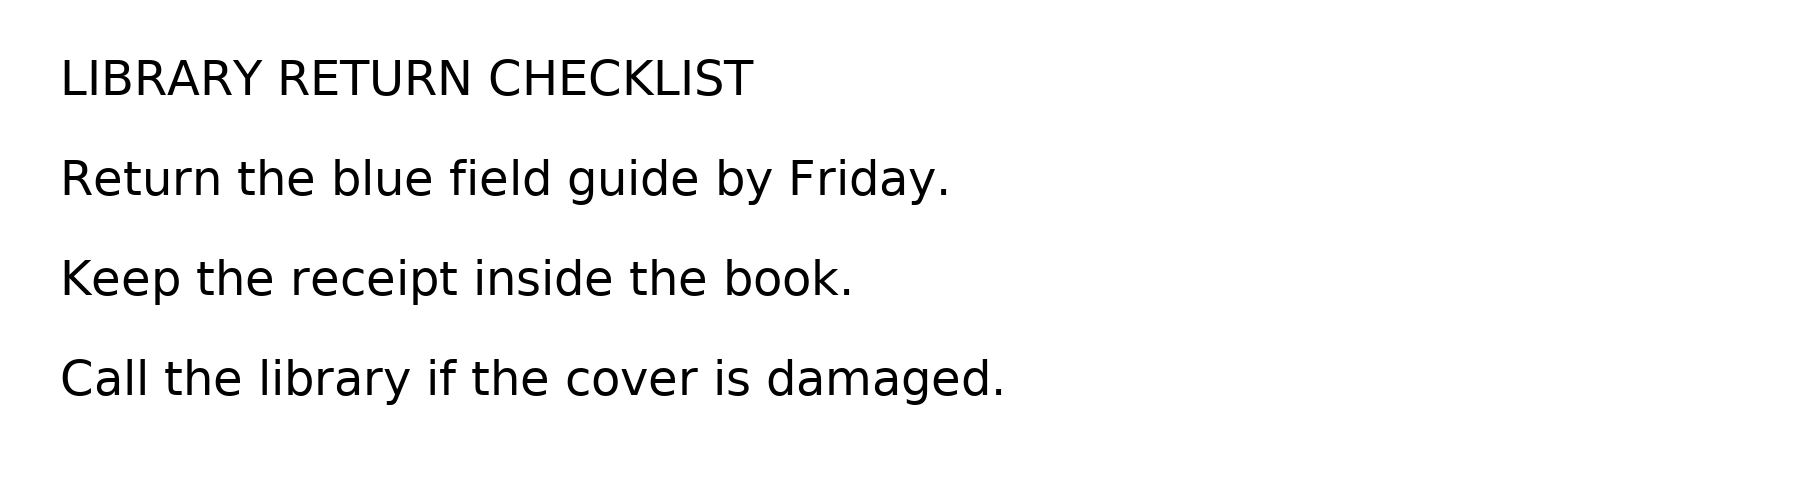

In [6]:
display(Image(filename="assets/scan-card.png", width=900))

In [7]:
%%sql
CREATE TABLE scan_result AS
SELECT tika.main.detect_mime('assets/scan-card.png') AS detected_mime,
 tika.main.ocr('assets/scan-card.png') AS recognized_text;
CREATE TABLE scan_audit AS
SELECT *,trim(regexp_replace(recognized_text,'\s+',' ','g')) AS normalized_text,
 'LIBRARY RETURN CHECKLIST Return the blue field guide by Friday. Keep the receipt inside the book. Call the library if the cover is damaged.' AS expected_text
FROM scan_result;
SELECT detected_mime,recognized_text FROM scan_audit;

,detected_mime,recognized_text
0,image/png,LIBRARY RETURN CHECKLIST\nReturn the blue fiel...


In [8]:
%%sql scan_check <<
SELECT detected_mime,length(expected_text) AS expected_characters,
 length(normalized_text) AS recognized_characters,
 array_length(string_split(expected_text,' ')) AS expected_tokens,
 array_length(string_split(normalized_text,' ')) AS recognized_tokens,
 lower(normalized_text)=lower(expected_text) AS exact_normalized_match
FROM scan_audit;

In [9]:
display(scan_check)
r = scan_check.iloc[0]
assert r.detected_mime == "image/png" and bool(r.exact_normalized_match)
assert int(r.expected_tokens) == len(scan_manifest["expected_tokens"])
prose(
    f"All **{int(r.expected_tokens)} reference tokens** are preserved in order after whitespace/case normalization. "
    "The clean card matches its authored reference. This does not test low resolution, rotation, handwriting, reading order across columns or other languages."
)

,detected_mime,expected_characters,recognized_characters,expected_tokens,recognized_tokens,exact_normalized_match
0,image/png,139,139,24,24,True


All **24 reference tokens** are preserved in order after whitespace/case normalization. The clean card matches its authored reference. This does not test low resolution, rotation, handwriting, reading order across columns or other languages.

### Route text only after retaining its representation

The queue combines the recovered card with authored English, French and German
sentences, the ambiguous `OK`, an identifier, blank text and SQL NULL. A source label
is kept for every row. Known sentence languages provide narrow sanity checks; `OK`
has no asserted correct language. Empty/undetectable input is not scored as zero.

Call `detect_lang` and `detect_lang_conf` on the same stored text, materialize both,
then apply the local rule. These two calls run the same detector independently;
confidence is not an OCR score. A convincing label can coexist with incomplete OCR.

In [10]:
%%sql
CREATE TABLE language_queue AS
SELECT 'SCAN' AS source_id,'Recovered synthetic card' AS source_kind,normalized_text AS body,'en' AS expected_language FROM scan_audit
UNION ALL SELECT * FROM (VALUES
 ('EN','Authored English','The library keeps the borrowed books in a quiet room near the main entrance. Please return every book before Friday so another reader can borrow it.','en'),
 ('FR','Authored French','La bibliothèque conserve les livres empruntés dans une salle calme près de l’entrée principale. Veuillez rendre chaque livre avant vendredi pour qu’un autre lecteur puisse l’emprunter.','fr'),
 ('DE','Authored German','Die Bibliothek bewahrt die ausgeliehenen Bücher in einem ruhigen Raum neben dem Haupteingang auf. Bitte geben Sie jedes Buch bis Freitag zurück, damit ein anderer Leser es ausleihen kann.','de'),
 ('SHORT','Ambiguous two-letter text','OK',NULL),
 ('CODE','Identifier only','PO-88213',NULL),
 ('BLANK','Empty text','',NULL),
 ('NULL','Missing text',NULL,NULL)
) t(source_id,source_kind,body,expected_language);
CREATE TABLE detected_languages AS
SELECT *,tika.main.detect_lang(body) AS detected_language,
 tika.main.detect_lang_conf(body) AS confidence FROM language_queue;
CREATE TABLE language_routing AS
SELECT *,CASE WHEN detected_language IS NULL OR confidence IS NULL THEN 'Unknown'
 WHEN confidence>={{ MIN_LANGUAGE_CONFIDENCE }} THEN 'Retain label' ELSE 'Review score' END AS routing_state
FROM detected_languages;

,Count


In [11]:
%%sql routes <<
SELECT source_id,source_kind,length(body) AS characters,expected_language,detected_language,
 confidence,routing_state FROM language_routing
ORDER BY CASE source_id WHEN 'SCAN' THEN 0 WHEN 'EN' THEN 1 WHEN 'FR' THEN 2 WHEN 'DE' THEN 3 WHEN 'SHORT' THEN 4 WHEN 'CODE' THEN 5 WHEN 'BLANK' THEN 6 ELSE 7 END;

,source_id,source_kind,characters,expected_language,detected_language,confidence,routing_state
0,SCAN,Recovered synthetic card,139,en,en,0.999997,Retain label
1,EN,Authored English,148,en,en,0.999997,Retain label
2,FR,Authored French,184,fr,fr,0.999999,Retain label
3,DE,Authored German,187,de,de,0.999998,Retain label
4,SHORT,Ambiguous two-letter text,2,None,de,0.102213,Review score
5,CODE,Identifier only,8,None,None,NaN,Unknown
6,BLANK,Empty text,0,None,None,NaN,Unknown
7,NULL,Missing text,<NA>,None,None,NaN,Unknown


At **0.8**, **4 of 8 queue rows** retain a language label. The two-letter OK returns **de** with score **0.102** and is assigned **Review score**. That result illustrates ambiguity, not evidence that OK is German. Identifier, blank and missing text keep unknown scores.

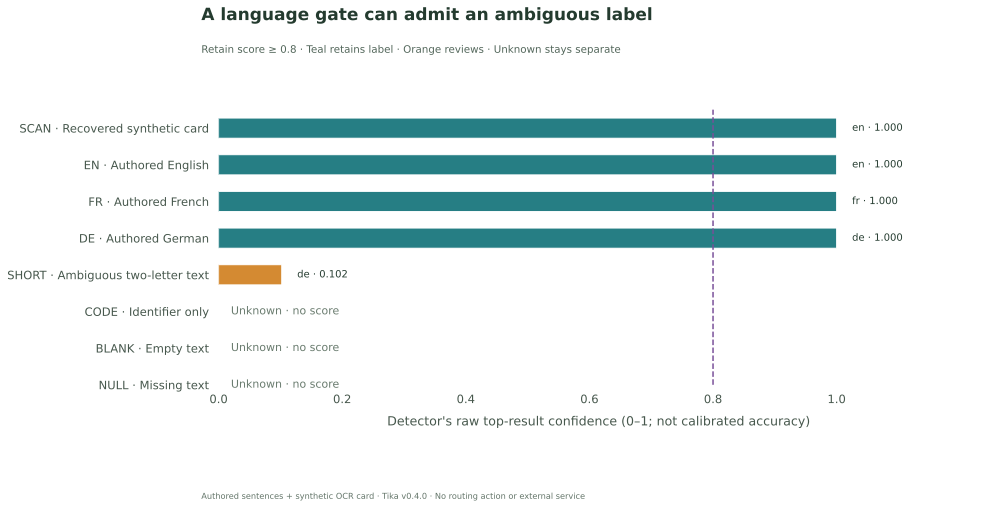

In [12]:
display(routes)
retained = int((routes.routing_state == "Retain label").sum())
short = routes.loc[routes.source_id == "SHORT"].iloc[0]
prose(
    f"At **{MIN_LANGUAGE_CONFIDENCE:g}**, **{retained} of {len(routes)} queue rows** retain a language label. "
    f"The two-letter OK returns **{short.detected_language}** with score **{short.confidence:.3f}** and is assigned **{short.routing_state}**. "
    "That result illustrates ambiguity, not evidence that OK is German. Identifier, blank and missing text keep unknown scores."
)
fig, ax = plt.subplots(figsize=(12, 7.5))
labels = [f"{r.source_id} · {r.source_kind}" for r in routes.itertuples()]
colors = {"Retain label": "#267e84", "Review score": "#d48a32", "Unknown": "#87928b"}
for i, row in enumerate(routes.itertuples()):
    if pd.isna(row.confidence):
        ax.text(
            0.02,
            i,
            "Unknown · no score",
            va="center",
            color="#697b6e",
            fontsize=11,
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5},
        )
    else:
        ax.barh(i, row.confidence, color=colors[row.routing_state], height=0.55)
        ax.text(
            row.confidence + 0.025,
            i,
            f"{row.detected_language} · {row.confidence:.3f}",
            va="center",
            fontsize=10,
        )
ax.set_yticks(range(len(labels)), labels)
ax.invert_yaxis()
ax.set_xlim(0, 1.23)
ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.axvline(MIN_LANGUAGE_CONFIDENCE, color="#784e98", linewidth=1.5, linestyle="--")
ax.set_xlabel("Detector's raw top-result confidence (0–1; not calibrated accuracy)")
finish(
    fig,
    "A language gate can admit an ambiguous label",
    f"Retain score ≥ {MIN_LANGUAGE_CONFIDENCE:g} · Teal retains label · Orange reviews · Unknown stays separate",
    "Authored sentences + synthetic OCR card · Tika v0.4.0 · No routing action or external service",
    name=f"language-routing-{MIN_LANGUAGE_CONFIDENCE:g}",
)

### Reconcile recognition and routing independently

The checks retain all eight source IDs and keep unknown scores distinct. They assert
this card's exact normalized text, the three authored sentence languages and the
valid score range. They do not assert a correct language for the two-letter text or
claim that the threshold is calibrated for production documents.

In [13]:
%%sql checks <<
SELECT 'Eight distinct source IDs retained' AS check_name,
 (SELECT count(*)=8 AND count(DISTINCT source_id)=8 FROM language_routing) AS passed
UNION ALL SELECT 'OCR card is a PNG', (SELECT detected_mime='image/png' FROM scan_audit)
UNION ALL SELECT 'Clean card exact normalized reference', (SELECT lower(normalized_text)=lower(expected_text) FROM scan_audit)
UNION ALL SELECT 'Card recognition is nonempty', (SELECT length(normalized_text)>0 FROM scan_audit)
UNION ALL SELECT 'Known sentence languages agree', NOT EXISTS(SELECT 1 FROM language_routing WHERE expected_language IS NOT NULL AND detected_language IS DISTINCT FROM expected_language)
UNION ALL SELECT 'Known scores are in range', NOT EXISTS(SELECT 1 FROM language_routing WHERE confidence IS NOT NULL AND NOT confidence BETWEEN 0 AND 1)
UNION ALL SELECT 'Blank and missing input remain unknown', (SELECT count(*)=2 FROM language_routing WHERE source_id IN ('BLANK','NULL') AND detected_language IS NULL AND confidence IS NULL AND routing_state='Unknown')
UNION ALL SELECT 'Identifier is not assigned a language', (SELECT detected_language IS NULL AND confidence IS NULL FROM language_routing WHERE source_id='CODE')
UNION ALL SELECT 'Retained labels satisfy the policy', NOT EXISTS(SELECT 1 FROM language_routing WHERE routing_state='Retain label' AND (confidence<{{ MIN_LANGUAGE_CONFIDENCE }} OR detected_language IS NULL))
UNION ALL SELECT 'Review scores stay below policy', NOT EXISTS(SELECT 1 FROM language_routing WHERE routing_state='Review score' AND confidence>={{ MIN_LANGUAGE_CONFIDENCE }})
UNION ALL SELECT 'Unknown scores are not zero filled', (SELECT count(*)=3 FROM language_routing WHERE confidence IS NULL)
UNION ALL SELECT 'Routing partitions all sources', (SELECT count(*) FILTER(WHERE routing_state='Retain label')+count(*) FILTER(WHERE routing_state='Review score')+count(*) FILTER(WHERE routing_state='Unknown')=count(*) FROM language_routing);

In [14]:
display(checks)
assert len(checks) == 12 and checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
prose(
    f"**{len(checks)} SQL checks passed**, with image hash and reference-token controls. OCR and language evidence remain separate."
)

,check_name,passed
0,Eight distinct source IDs retained,True
1,OCR card is a PNG,True
2,Clean card exact normalized reference,True
3,Card recognition is nonempty,True
4,Known sentence languages agree,True
5,Known scores are in range,True
6,Blank and missing input remain unknown,True
7,Identifier is not assigned a language,True
8,Retained labels satisfy the policy,True
9,Review scores stay below policy,True


**12 SQL checks passed**, with image hash and reference-token controls. OCR and language evidence remain separate.

### Experiment · lower the confidence gate

Change only `MIN_LANGUAGE_CONFIDENCE` from `0.8` to `0.05`, restart, and run all.
Predict what happens to the two-letter row. Its detected code and low score should
stay fixed while its route changes. The recovered card, exact reference comparison,
three long sentences and three unknown rows must stay unchanged.

A looser threshold can increase label coverage without adding evidence about language.
This example makes that tradeoff visible; it does not choose a production cutoff or
send any document onward. Reset to `0.8` for the saved default.

In [15]:
session.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-tika](https://github.com/Query-farm/vgi-tika)